In [66]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [67]:
df = pd.read_csv("smartcart_customers.csv")

In [68]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,43,182,42,118,247,2,9,3,4,5,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,0,30,0,0,8,7,8,2,5,7,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,48,217,32,12,24,1,2,3,13,6,0,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,30,214,80,30,61,2,6,5,10,3,0,0


In [69]:
df.isnull().sum()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

DATA PREPROCESSING

1 HANDLE MISSING VALUES


In [70]:
df["Income"] = df["Income"].fillna(df["Income"].median())

FEATURE INGINEERING

In [71]:
# age
df["age"] = 2026 - df["Year_Birth"]

In [72]:
# customer joining date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

reference = df["Dt_Customer"].max()

df["Dt_Customer_tenure_days"] = (reference - df["Dt_Customer"]).dt.days

In [73]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'age', 'Dt_Customer_tenure_days'],
      dtype='str')

In [74]:
#spending

df["Total_spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [75]:
# children

df["Total_children"] = df["Kidhome"] + df["Teenhome"]

In [76]:
# education

df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "grauduate",
    "Master": "Postgratuade", "PHD": "Postgratuade"
})

df["Education"].value_counts() 

Education
grauduate        1127
PhD               486
Postgratuade      370
Undergraduate     257
Name: count, dtype: int64

In [77]:
# marital status

df["living_with"] = df["Marital_Status"].replace({
    "Married": "partner", "Together": "partner",
    "Single": "Alone", "Divorced":"Alone",
    "Widow": "Alone", "Absurd": "Alone", "YOLO":"Alone"
})



DROP COLUMNS

In [78]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'age', 'Dt_Customer_tenure_days',
       'Total_spending', 'Total_children', 'living_with'],
      dtype='str')

In [79]:
clos = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spending_cols =["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts" ,"MntGoldProds"]

cols_To_clos = clos + spending_cols

df_cleans = df.drop(columns=cols_To_clos)


In [80]:
df_cleans.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'age',
       'Dt_Customer_tenure_days', 'Total_spending', 'Total_children',
       'living_with'],
      dtype='str')

OUTLIERS

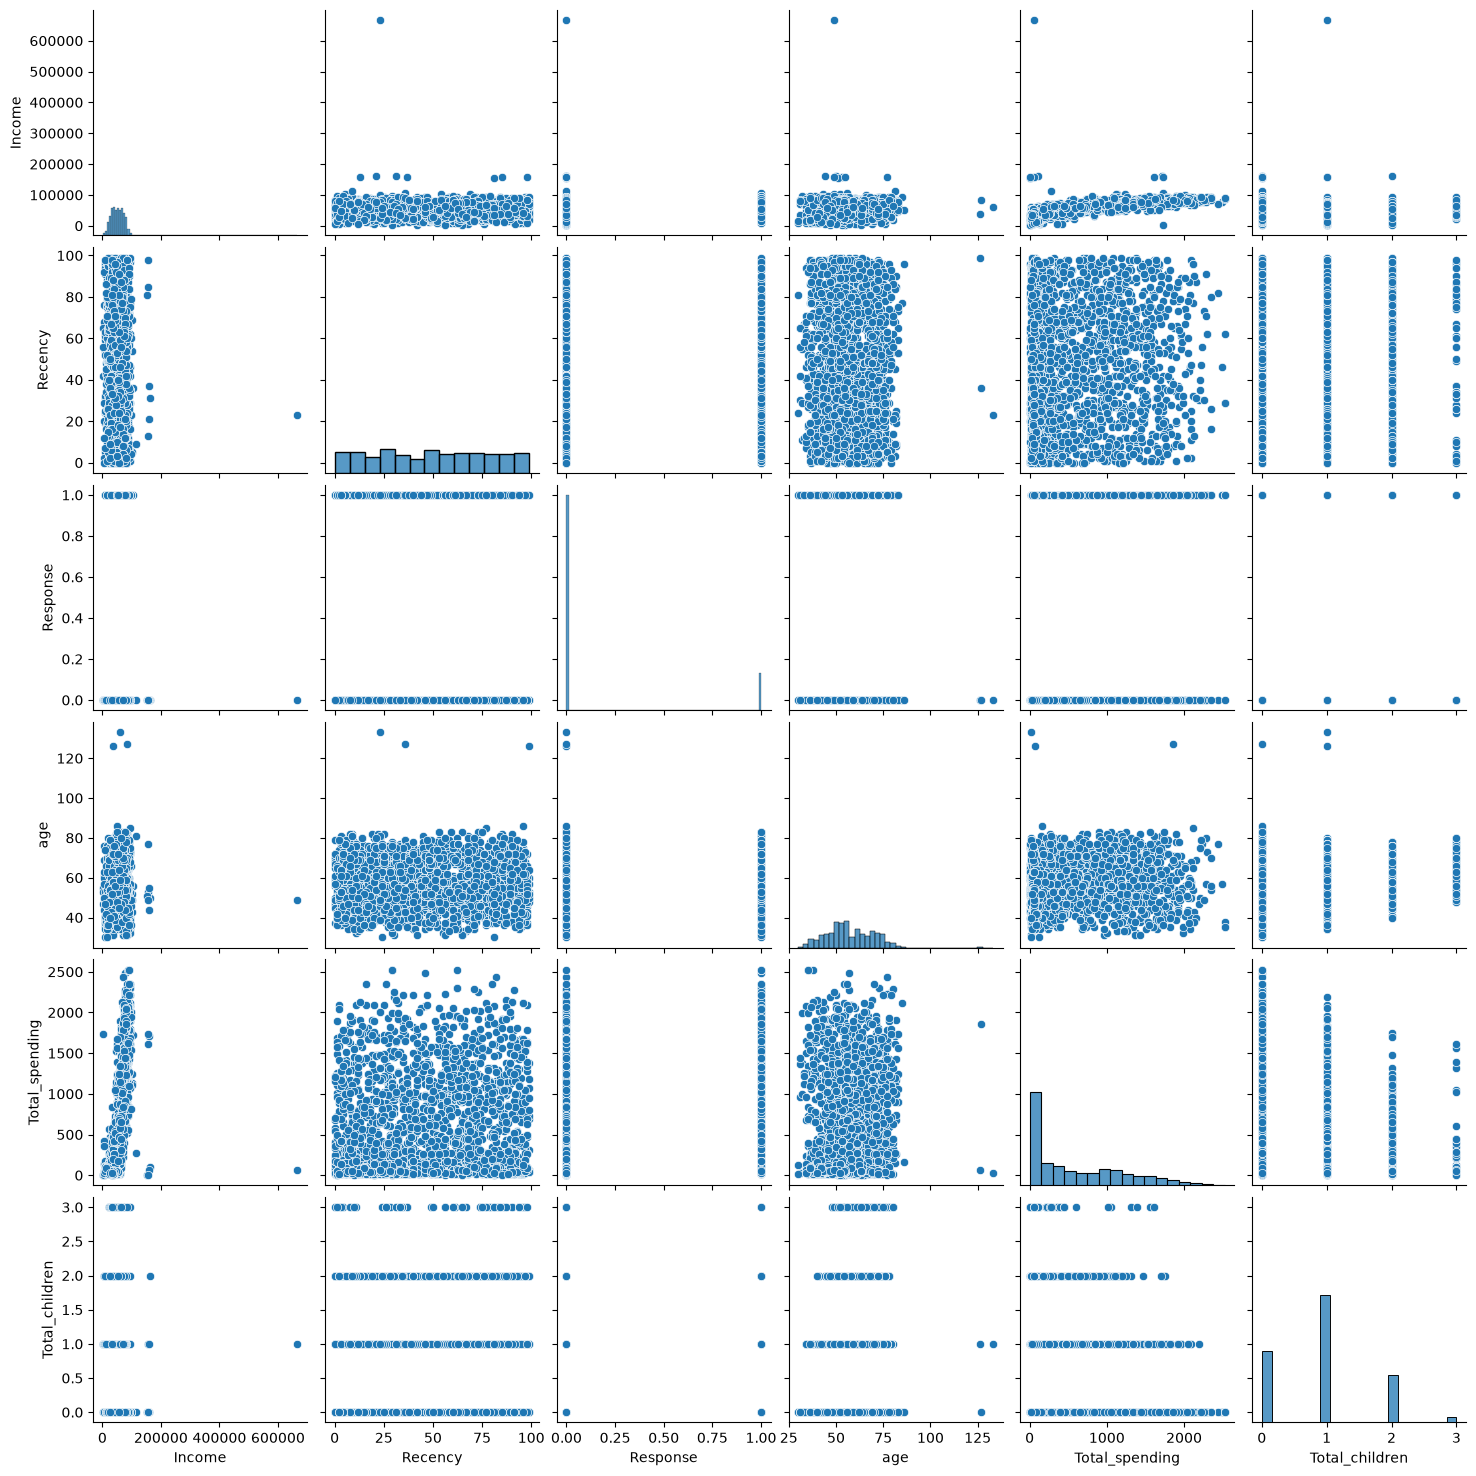

In [81]:
cols = ["Income" ,"Recency", "Response", "age", "Total_spending", "Total_children"]
# relaive plots of features - pairs plots

sns.pairplot(df_cleans[cols])

In [82]:
# remove outliers

print("data size with outliers", len(df_cleans))

df_cleans = df_cleans[ (df_cleans["age"] < 90)]
df_cleans = df_cleans[ (df_cleans["Income"] < 600_000)]

print("data size without outliers", len(df_cleans))

data size with outliers 2240
data size without outliers 2236


HEATMAP

In [83]:
corr = df_cleans.corr(numeric_only=True)

<Axes: >

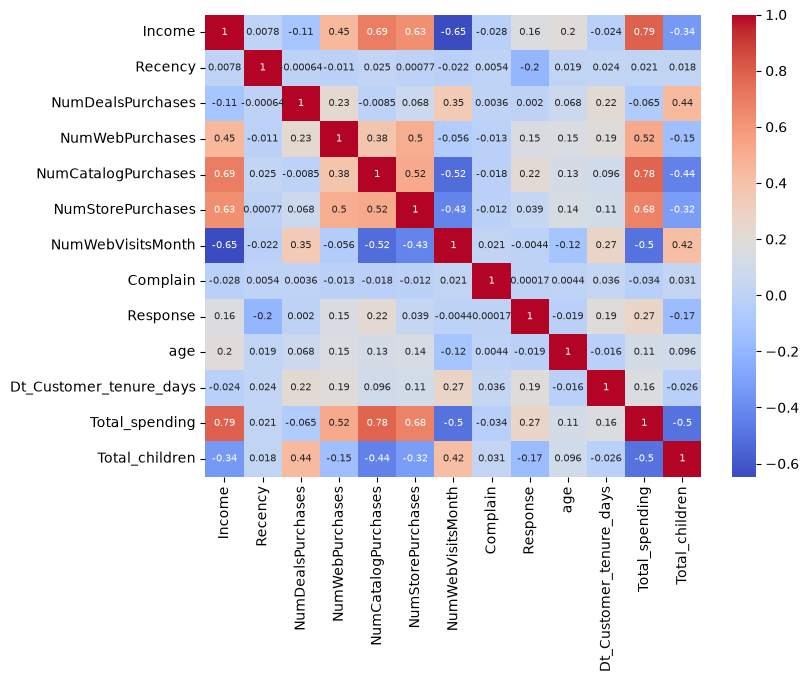

In [84]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size": 7},
    cmap="coolwarm"
)

ENCODING

In [85]:
from sklearn.preprocessing import OneHotEncoder

In [86]:
ohe = OneHotEncoder()

cat_cols = ["Education" ,"living_with"]

enc_col = ohe.fit_transform(df_cleans[cat_cols])

In [87]:
enc_df = pd.DataFrame(enc_col.toarray(), columns=ohe.get_feature_names_out(cat_cols), index=df_cleans.index)

In [88]:
df_encod = pd.concat([df_cleans.drop(columns=cat_cols),enc_df],axis=1)

In [89]:
df_encod

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Dt_Customer_tenure_days,Total_spending,Total_children,Education_PhD,Education_Postgratuade,Education_Undergraduate,Education_grauduate,living_with_Alone,living_with_partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,0.0,0.0,0.0,1.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,0.0,0.0,0.0,1.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,0.0,0.0,0.0,1.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,0.0,0.0,0.0,1.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,0.0,0.0,0.0,1.0,0.0,1.0
2236,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,1.0,0.0,0.0,0.0,0.0,1.0
2237,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,0.0,0.0,0.0,1.0,1.0,0.0
2238,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,0.0,1.0,0.0,0.0,0.0,1.0


SCALING

In [90]:
from sklearn.preprocessing  import StandardScaler

In [91]:
x = df_encod



In [92]:
sclar = StandardScaler()

x_scaled = sclar.fit_transform(x)

VISUALIZE

In [93]:
from sklearn.decomposition import PCA

In [94]:
pca = PCA(n_components=3)

x_pca = pca.fit_transform(x_scaled)

In [95]:
pca.explained_variance_ratio_

array([0.21946658, 0.10788256, 0.09588641])

Text(0.5, 0.92, '3d projestion')

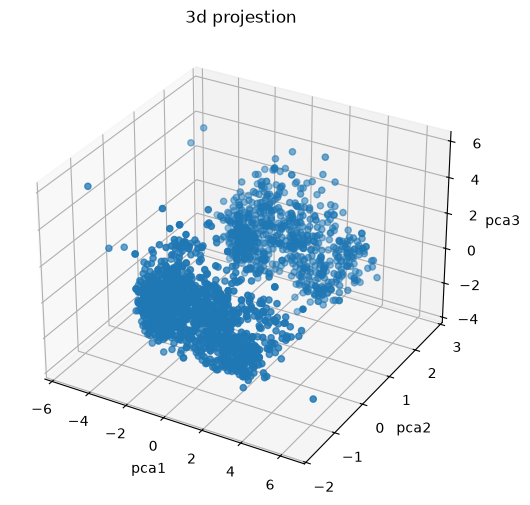

In [96]:
#plot
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(x_pca[:, 0] , x_pca[:, 1], x_pca[:, 2])

ax.set_xlabel("pca1")
ax.set_ylabel("pca2")
ax.set_zlabel("pca3")
ax.set_title("3d projestion")

In [97]:
pca.explained_variance_ratio_

array([0.21946658, 0.10788256, 0.09588641])


ANALYZE K VALUE
1 ELBOW METHOD

In [98]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [99]:
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k,random_state=42)
    kmeans.fit_predict(x_pca)
    wcss.append(kmeans.inertia_)



In [100]:
knee = KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing")
optimal_k = knee.elbow

In [101]:
print("best k =", optimal_k)

best k = 4


Text(0, 0.5, 'WCSS')

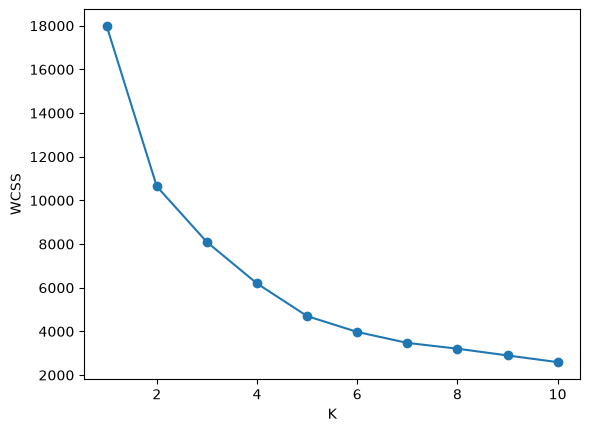

In [102]:
# plot

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("K")
plt.ylabel("WCSS")



2 SILHOUETTE SCORE

Text(0, 0.5, 'Silhouette score')

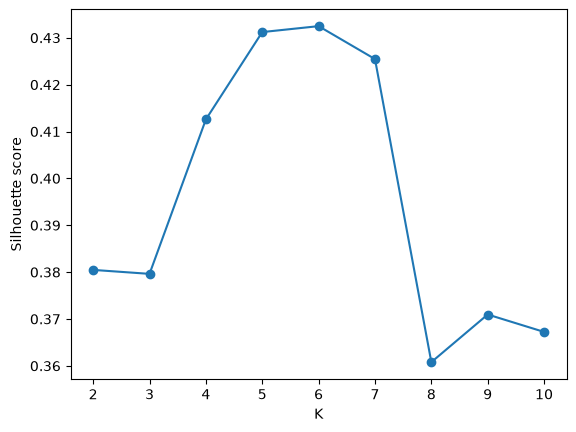

In [103]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(x_pca)
    score = silhouette_score(x_pca, labels)
    scores.append(score)

# plot
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette score")

Text(0, 0.5, 'SS')

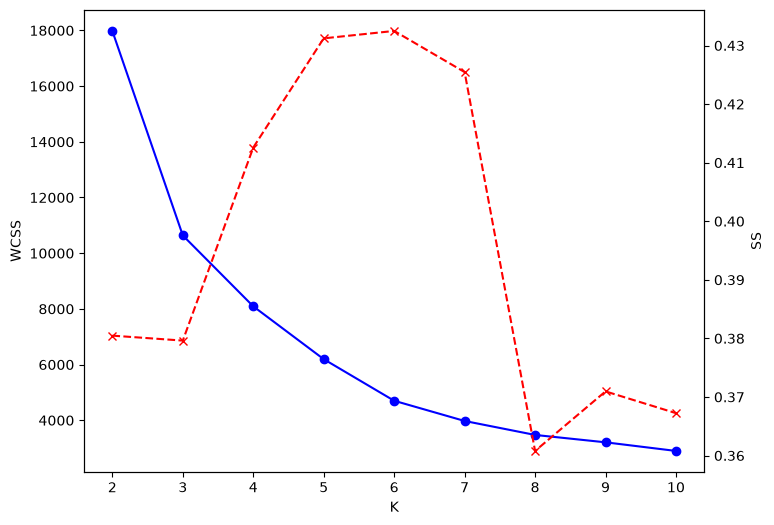

In [104]:
# combined plot

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(k_range, wcss[:len(k_range)], marker="o", color="blue") 
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker="x", color="red", linestyle="--")
ax2.set_ylabel("SS")

CLUSTERING


In [105]:
# K_means

kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(x_pca)

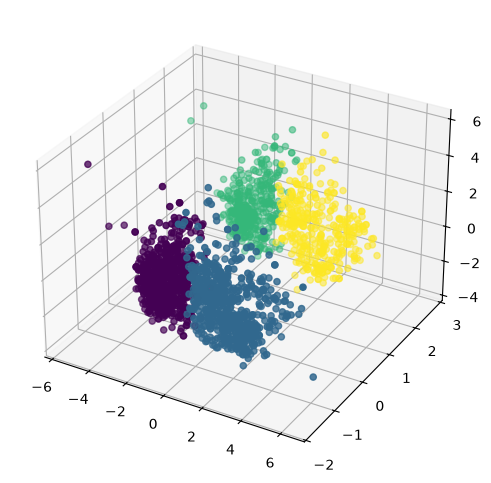

In [106]:
fig = plt.figure(figsize=(8, 6))


ax = fig.add_subplot(111, projection="3d")

ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2], c=labels_kmeans)

In [107]:
# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

In [108]:
agg_clf = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg_clf.fit_predict(x_pca)

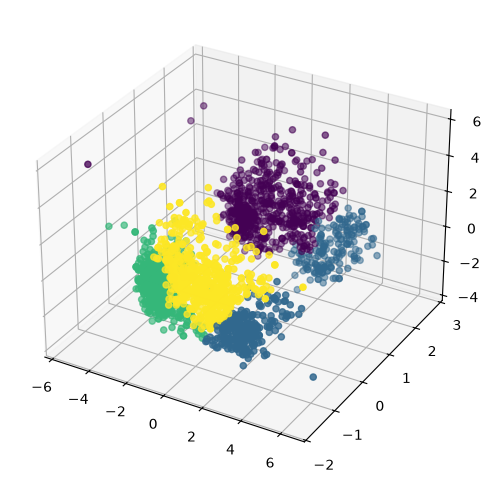

In [109]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2], c=labels_agg)


 CHARATERIZATION OF CLUSTERS

In [110]:
x["cluster"] = labels_agg

In [111]:
x.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,Dt_Customer_tenure_days,Total_spending,Total_children,Education_PhD,Education_Postgratuade,Education_Undergraduate,Education_grauduate,living_with_Alone,living_with_partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,0.0,0.0,0.0,1.0,1.0,0.0,0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,0.0,0.0,0.0,1.0,1.0,0.0,0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,0.0,0.0,0.0,1.0,0.0,1.0,3
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,0.0,0.0,0.0,1.0,0.0,1.0,2
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,1.0,0.0,0.0,0.0,0.0,1.0,3


<Axes: xlabel='cluster', ylabel='count'>

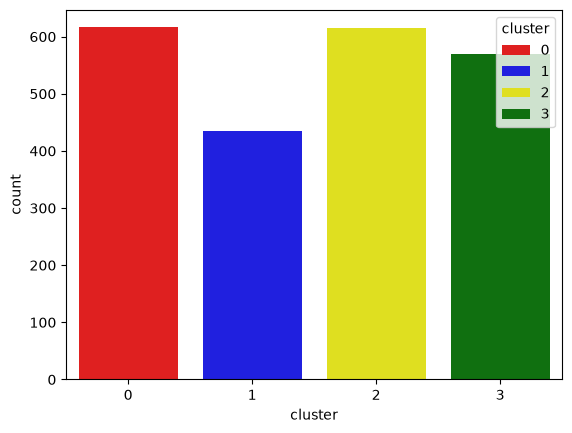

In [112]:
pal = ["red", "blue", "yellow", "green"]

sns.countplot(x=x["cluster"], palette=pal, hue=x["cluster"])

<Axes: xlabel='Total_spending', ylabel='Income'>

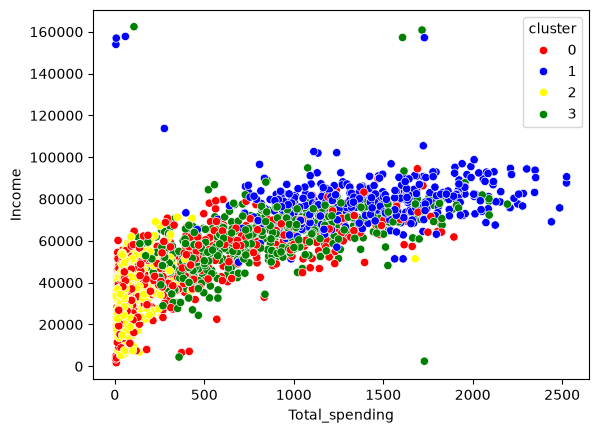

In [113]:
# Income & Spending patterns

sns.scatterplot(x=x["Total_spending"], y=x["Income"], hue=x["cluster"], palette=pal)

In [115]:
import pandas as pd 

pd.set_option("display.max_columns",None)
pd.set_option("display.width",None)

In [116]:
# Cluster Summary

cluster_summary = x.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        44268.955357  47.987013           2.655844         3.892857   
1        78763.178161  51.204598           0.967816         4.705747   
2        33711.121951  49.100813           1.865041         1.920325   
3        59477.273684  48.759649           3.503509         6.164912   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   1.740260           4.975649           6.232143  0.009740   
1                   6.193103           8.471264           2.133333  0.004598   
2                   0.469919           3.156098           6.416260  0.011382   
3                   3.333333           7.487719           5.578947  0.008772   

         Response        age  Dt_Customer_tenure_days  Total_spending  \
cluster      